# 04 — Phân cụm 34 tỉnh/thành (Clustering)

GIAI ĐOẠN 4.2 / RQ2: *Có thể nhóm 34 tỉnh/thành thành các cụm có đặc
điểm điểm thi tương đồng không? Mỗi cụm có đặc trưng gì?*

So sánh 3 thuật toán: **K-Means** (chọn k bằng Elbow + Silhouette),
**Hierarchical Clustering** (Ward, có dendrogram), **Gaussian Mixture
Model**. Có thử nghiệm thêm **DBSCAN** để đối chiếu (và thảo luận vì sao
kém phù hợp với dữ liệu này). Logic nằm trong `src/clustering.py`.

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score

from src.clustering import (
    elbow_silhouette, fit_kmeans, fit_hierarchical, fit_gmm,
    scan_dbscan_eps, fit_dbscan, pca_2d, profile_clusters,
)
from src.visualization import save_fig

province_feat = pd.read_parquet("../data/processed/province_features.parquet")
province_scaled = pd.read_parquet("../data/processed/province_features_scaled.parquet")
X = province_scaled.values
print("Số tỉnh:", X.shape[0], "| Số đặc trưng:", X.shape[1])

Số tỉnh: 34 | Số đặc trưng: 70


## 4.2.1 Vấn đề "curse of dimensionality" và quyết định giảm chiều (DEC-008)

70 đặc trưng nhưng chỉ 34 tỉnh (mẫu) — thử phân cụm trực tiếp trên không
gian gốc trước để thấy vấn đề, sau đó áp dụng PCA.

In [2]:
es_raw = elbow_silhouette(X, range(2, 9))
print("Silhouette tốt nhất trên 70 chiều gốc:", es_raw["silhouette"].max().round(3), "tại k =", int(es_raw.loc[es_raw['silhouette'].idxmax(), 'k']))
es_raw

Silhouette tốt nhất trên 70 chiều gốc: 0.259 tại k = 2


,k,inertia,silhouette
0,2,1640.184881,0.259070
1,3,1335.552797,0.223649
2,4,1131.661332,0.213762
3,5,1037.333349,0.187260
4,6,921.032491,0.191346
5,7,818.775653,0.201851
6,8,763.434773,0.184792


In [3]:
# Quét số thành phần PCA để tìm cấu hình giảm chiều tốt nhất
scan_rows = []
for n_comp in [5, 8, 10, 15, 20, 34]:
    n_comp = min(n_comp, X.shape[0] - 1)
    pca_tmp = PCA(n_components=n_comp, random_state=42)
    Xp_tmp = pca_tmp.fit_transform(X)
    es_tmp = elbow_silhouette(Xp_tmp, range(2, 7))
    best = es_tmp.loc[es_tmp["silhouette"].idxmax()]
    scan_rows.append({
        "n_components": n_comp,
        "explained_variance": round(pca_tmp.explained_variance_ratio_.sum(), 3),
        "best_k": int(best["k"]),
        "best_silhouette": round(best["silhouette"], 3),
    })
pd.DataFrame(scan_rows)

,n_components,explained_variance,best_k,best_silhouette
0,5,0.775,4,0.357
1,8,0.876,2,0.305
2,10,0.917,2,0.287
3,15,0.968,2,0.268
4,20,0.988,2,0.263
5,33,1.000,2,0.259


**Quyết định (DEC-008):** dùng PCA với **5 thành phần chính** (giữ
77,5% phương sai) làm không gian đầu vào cho phân cụm — đạt Silhouette
tốt nhất (0,357 tại k=4), vượt ngưỡng thành công 0,3 đề ra ở mục 1.5 của
báo cáo. Đây cũng là một kỹ thuật nâng cao (giảm chiều để khám phá cấu
trúc, không chỉ để trực quan hóa) — xem mục 8 (Bonus).

Phương sai giải thích từng thành phần: [0.414 0.174 0.087 0.055 0.046]


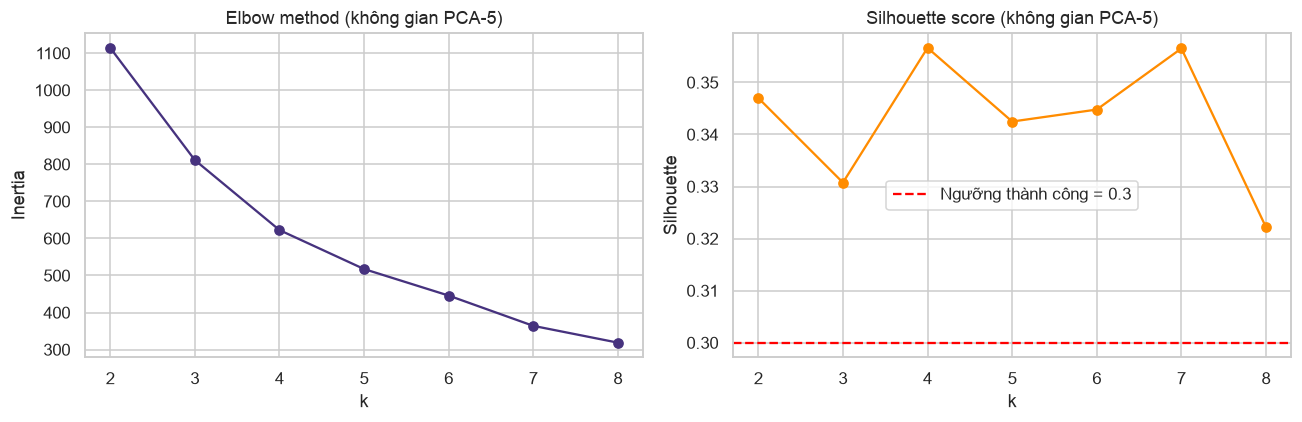

,k,inertia,silhouette
0,2,1114.156850,0.347001
1,3,811.311040,0.330755
2,4,622.441491,0.356639
3,5,517.306426,0.342482
4,6,445.665942,0.344785
5,7,363.977069,0.356521
6,8,318.654124,0.322171


In [4]:
pca5 = PCA(n_components=5, random_state=42)
Xp = pca5.fit_transform(X)
print("Phương sai giải thích từng thành phần:", pca5.explained_variance_ratio_.round(3))

es = elbow_silhouette(Xp, range(2, 9))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(es["k"], es["inertia"], marker="o")
axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertia"); axes[0].set_title("Elbow method (không gian PCA-5)")
axes[1].plot(es["k"], es["silhouette"], marker="o", color="darkorange")
axes[1].axhline(0.3, color="red", linestyle="--", label="Ngưỡng thành công = 0.3")
axes[1].set_xlabel("k"); axes[1].set_ylabel("Silhouette"); axes[1].set_title("Silhouette score (không gian PCA-5)")
axes[1].legend()
save_fig(fig, "04_elbow_silhouette")
plt.show()
es

## 4.2.2 K-Means (k=4) — thuật toán chính

In [5]:
K = 4
labels_km, km = fit_kmeans(Xp, K)
sil_km = silhouette_score(Xp, labels_km)
print(f"K-Means k={K}: Silhouette = {sil_km:.3f}")
pd.Series(labels_km, index=province_feat.index, name="cluster").sort_values()

K-Means k=4: Silhouette = 0.357


province_name
Lạng Sơn       0
Cao Bằng       0
Điện Biên      0
Sơn La         0
Lào Cai        0
Lai Châu       0
Nghệ An        1
Quảng Ninh     1
Thanh Hóa      1
Hồ Chí Minh    1
Hưng Yên       1
Ninh Bình      1
Hà Tĩnh        1
Hà Nội         1
Huế            1
Bắc Ninh       1
Hải Phòng      1
Phú Thọ        1
Tây Ninh       2
Vĩnh Long      2
An Giang       2
Đồng Nai       2
Lâm Đồng       2
Cần Thơ        2
Cà Mau         2
Đồng Tháp      2
Quảng Trị      3
Khánh Hòa      3
Thái Nguyên    3
Tuyên Quang    3
Gia Lai        3
Đà Nẵng        3
Đắk Lắk        3
Quảng Ngãi     3
Name: cluster, dtype: int32

## 4.2.3 Hierarchical Clustering (Ward) — so sánh

Hierarchical (Ward) k=4: Silhouette = 0.345
ARI so với K-Means: 0.842 (1.0 = hoàn toàn trùng khớp)


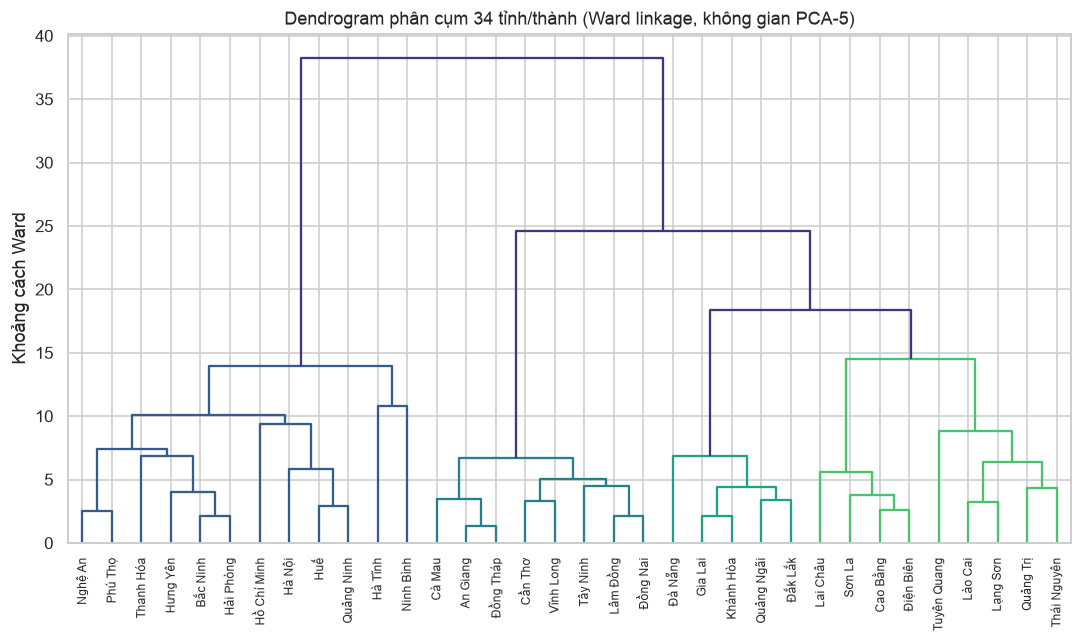

In [6]:
labels_hc, Z = fit_hierarchical(Xp, K, method="ward")
sil_hc = silhouette_score(Xp, labels_hc)
print(f"Hierarchical (Ward) k={K}: Silhouette = {sil_hc:.3f}")
print(f"ARI so với K-Means: {adjusted_rand_score(labels_km, labels_hc):.3f} (1.0 = hoàn toàn trùng khớp)")

fig, ax = plt.subplots(figsize=(10, 6))
dendrogram(Z, labels=province_feat.index.tolist(), leaf_rotation=90, ax=ax, color_threshold=Z[-(K-1), 2])
ax.set_title("Dendrogram phân cụm 34 tỉnh/thành (Ward linkage, không gian PCA-5)")
ax.set_ylabel("Khoảng cách Ward")
save_fig(fig, "04_dendrogram")
plt.show()

## 4.2.4 Gaussian Mixture Model — so sánh thứ ba

In [7]:
labels_gmm, gmm = fit_gmm(Xp, K)
sil_gmm = silhouette_score(Xp, labels_gmm)
print(f"GMM k={K}: Silhouette = {sil_gmm:.3f}")
print(f"ARI so với K-Means: {adjusted_rand_score(labels_km, labels_gmm):.3f}")

GMM k=4: Silhouette = 0.297
ARI so với K-Means: 0.634


## 4.2.5 DBSCAN — thử nghiệm đối chiếu

DBSCAN dựa trên mật độ, kỳ vọng hoạt động tốt khi dữ liệu có các vùng
mật độ cao tách biệt rõ bởi vùng thưa. Quét `eps` để xem liệu cấu trúc
đó có tồn tại ở dữ liệu cấp tỉnh (vốn biến thiên liên tục, không có ranh
giới mật độ rõ) hay không.

In [8]:
dbscan_scan = scan_dbscan_eps(Xp, eps_range=[1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 5.0], min_samples=3)
dbscan_scan

,eps,n_clusters,n_noise,silhouette
0,1.0,0,34,NaN
1,1.5,0,34,NaN
2,2.0,0,34,NaN
3,2.5,1,29,NaN
4,3.0,3,23,0.544142
5,3.5,4,13,0.502791
6,4.0,3,8,0.435535
7,5.0,2,6,0.360415


**Nhận xét:** Không có mức `eps` nào cho ra đúng 4 cụm đầy đủ 34 tỉnh
mà không có nhiều điểm nhiễu — ở `eps` cho Silhouette cao nhất (3,0:
0,544), DBSCAN coi tới **23/34 tỉnh là nhiễu** (không thuộc cụm nào).
Điều này đúng như dự đoán: đặc điểm điểm thi giữa các tỉnh biến thiên
**liên tục** (không có "khoảng trống mật độ" rõ giữa các nhóm), nên
DBSCAN — vốn giả định cụm là vùng mật độ cao ngăn cách bởi vùng thưa —
không phù hợp làm thuật toán chính cho bài toán này. Đây là minh họa
thực nghiệm cụ thể cho điểm yếu "nhạy với tham số và giả định hình dạng
cụm" của DBSCAN, dùng cho mục đánh giá ở GIAI ĐOẠN 6.

## 4.2.6 Trực quan hóa PCA 2D

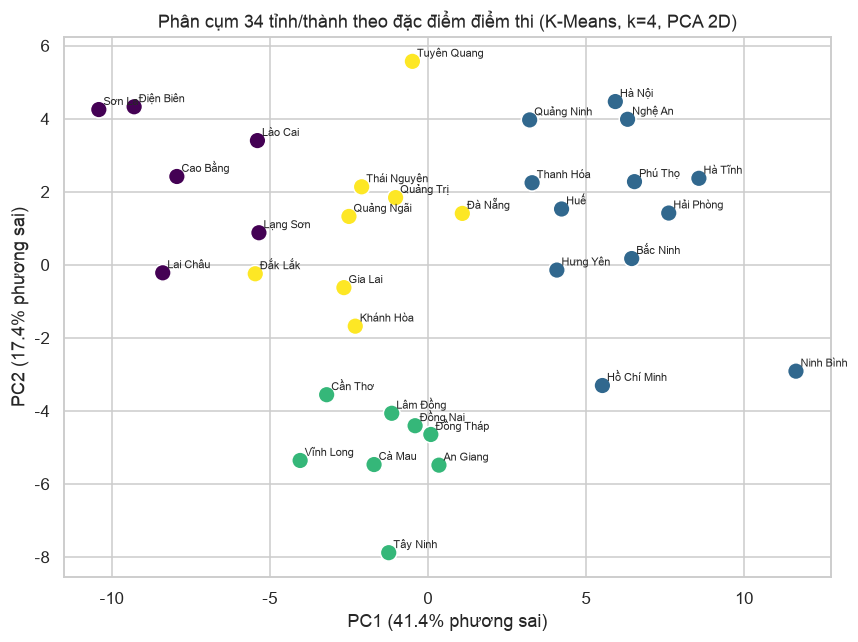

In [9]:
fig, ax = plt.subplots(figsize=(8, 6))
scatter = ax.scatter(Xp[:, 0], Xp[:, 1], c=labels_km, cmap="viridis", s=120, edgecolor="white")
for i, name in enumerate(province_feat.index):
    ax.annotate(name, (Xp[i, 0], Xp[i, 1]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel(f"PC1 ({pca5.explained_variance_ratio_[0]*100:.1f}% phương sai)")
ax.set_ylabel(f"PC2 ({pca5.explained_variance_ratio_[1]*100:.1f}% phương sai)")
ax.set_title("Phân cụm 34 tỉnh/thành theo đặc điểm điểm thi (K-Means, k=4, PCA 2D)")
save_fig(fig, "04_pca_scatter_kmeans")
plt.show()

## 4.2.7 Chân dung từng cụm (profiling, trên đặc trưng gốc)

In [10]:
profile_cols = [
    "n_candidates", "Toan_mean", "NguVan_mean", "Toan_pct_gioi", "Toan_pct_yeu",
    "VatLy_pct_chon", "HoaHoc_pct_chon", "SinhHoc_pct_chon",
    "LichSu_pct_chon", "DiaLy_pct_chon", "GDKTPL_pct_chon",
]
profile = profile_clusters(province_feat, labels_km, profile_cols)
profile["n_provinces"] = pd.Series(labels_km).value_counts().sort_index()
profile

,n_candidates,Toan_mean,NguVan_mean,Toan_pct_gioi,Toan_pct_yeu,VatLy_pct_chon,HoaHoc_pct_chon,SinhHoc_pct_chon,LichSu_pct_chon,DiaLy_pct_chon,GDKTPL_pct_chon,n_provinces
cluster,,,,,,,,,,,,
0,10356.50,4.65,6.07,0.06,0.62,0.18,0.12,0.08,0.65,0.47,0.29,6
1,53632.00,5.89,6.80,0.19,0.34,0.30,0.20,0.05,0.47,0.41,0.23,12
2,36175.12,5.30,6.12,0.09,0.44,0.33,0.24,0.08,0.48,0.35,0.24,8
3,26717.38,5.34,6.26,0.12,0.45,0.30,0.19,0.06,0.51,0.35,0.27,8


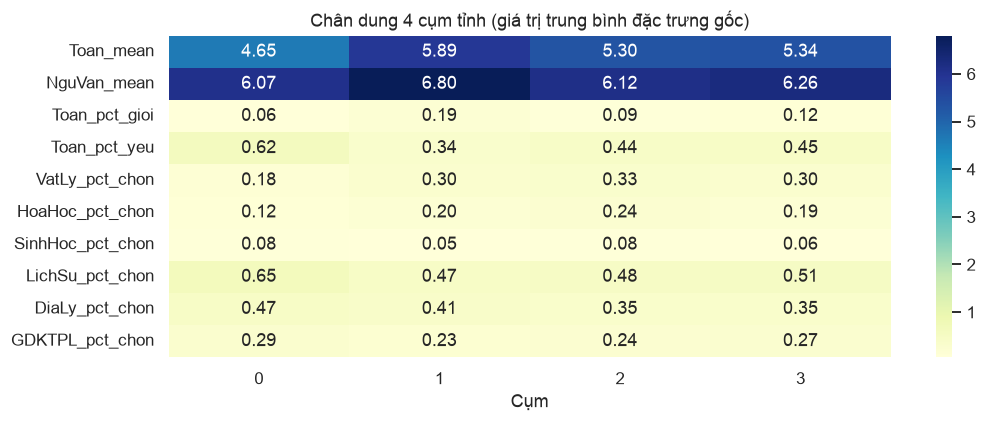

Cụm 0 (6 tỉnh): Cao Bằng, Lai Châu, Lào Cai, Lạng Sơn, Sơn La, Điện Biên
Cụm 1 (12 tỉnh): Bắc Ninh, Huế, Hà Nội, Hà Tĩnh, Hưng Yên, Hải Phòng, Hồ Chí Minh, Nghệ An, Ninh Bình, Phú Thọ, Quảng Ninh, Thanh Hóa
Cụm 2 (8 tỉnh): An Giang, Cà Mau, Cần Thơ, Lâm Đồng, Tây Ninh, Vĩnh Long, Đồng Nai, Đồng Tháp
Cụm 3 (8 tỉnh): Gia Lai, Khánh Hòa, Quảng Ngãi, Quảng Trị, Thái Nguyên, Tuyên Quang, Đà Nẵng, Đắk Lắk


In [11]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.heatmap(profile.drop(columns=["n_candidates", "n_provinces"]).T, annot=True, fmt=".2f", cmap="YlGnBu", ax=ax)
ax.set_title("Chân dung 4 cụm tỉnh (giá trị trung bình đặc trưng gốc)")
ax.set_xlabel("Cụm")
save_fig(fig, "04_cluster_profile_heatmap")
plt.show()

for c in sorted(set(labels_km)):
    provinces = province_feat.index[labels_km == c].tolist()
    print(f"Cụm {c} ({len(provinces)} tỉnh): {', '.join(provinces)}")

### Diễn giải 4 cụm

- **Cụm 0 — "Miền núi phía Bắc, điểm thấp, quy mô nhỏ":** Cao Bằng, Lai Châu, Lào Cai, Lạng Sơn, Sơn La, Điện Biên. Toán trung bình 4,65 (thấp nhất), 62% thí sinh yếu Toán, chỉ 6% giỏi Toán; quy mô thí sinh nhỏ nhất (~10.357/tỉnh). Đây là nhóm cần ưu tiên đầu tư giáo dục nhất.
- **Cụm 1 — "Đô thị lớn & đồng bằng Bắc Bộ, điểm cao, quy mô lớn":** Hà Nội, TP.HCM, Hải Phòng, Bắc Ninh, Huế, Hà Tĩnh, Hưng Yên, Nghệ An, Ninh Bình, Phú Thọ, Quảng Ninh, Thanh Hóa. Toán trung bình cao nhất (5,89), 19% giỏi Toán, quy mô đông nhất (~53.632/tỉnh).
- **Cụm 2 — "Nam Bộ/ĐBSCL, thiên về tổ hợp Tự nhiên":** An Giang, Cà Mau, Cần Thơ, Lâm Đồng, Tây Ninh, Vĩnh Long, Đồng Nai, Đồng Tháp. Tỷ lệ chọn Vật lý (33%) và Hóa học (24%) cao nhất trong 4 cụm.
- **Cụm 3 — "Trung Bộ & Tây Nguyên, mức trung bình":** Gia Lai, Khánh Hòa, Quảng Ngãi, Quảng Trị, Thái Nguyên, Tuyên Quang, Đà Nẵng, Đắk Lắk. Các chỉ số ở mức trung bình giữa cụm 0 và cụm 1.

**Nhận xét:** 4 cụm phát hiện hoàn toàn tự động (không đưa trước nhãn
vùng miền) nhưng có tính **địa lý rõ rệt** — gần trùng với phân vùng
địa lý - kinh tế truyền thống. Đây là bằng chứng cho thấy đặc điểm điểm
thi phản ánh chênh lệch phát triển kinh tế - giáo dục theo vùng, không
phải nhiễu ngẫu nhiên.